# Flywheel — session analysis

Load a session exported from the app (**History → session → Export JSON**), look at it from a few angles, replay it
stroke by stroke, and write a compact summary you can hand to Claude for coaching feedback.

**Use:** put your `.json` export in this folder (or anywhere) and set `PATH` below. Run all cells.
Needs `numpy`, `pandas` and `matplotlib`, which come with any Jupyter install.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import HTML, Markdown, display
import flywheel as fw

# the file to analyse; by default the newest export in this folder, else the bundled sample
exports = sorted([p for p in Path('.').glob('*.json') if not p.stem.endswith('_compact')], key=lambda p: p.stat().st_mtime)
PATH = exports[-1] if exports else Path('sample/flywheel-sample-1k.json')

s = fw.load(PATH)
print(f'{PATH.name}: {s.event["label"]} · {len(s.strokes)} strokes · {s.started:%Y-%m-%d %H:%M}')

flywheel-sample-1k.json: 1k · 103 strokes · 2026-11-05 21:05


## Result

In [2]:
pd.Series(fw.headline(s), name='').to_frame()

,
piece,1k
date,2026-11-05 21:05
time,3:42.2
distance_m,1001
avg_pace,1:51.0
avg_watts,257
max_watts,313
avg_rate_spm,28.0
strokes,103
m_per_stroke,9.72


## Splits
Time, pace and watts per split, with rate, stroke count and metres per stroke. Even split times mean even pacing.
At the same rate, more metres per stroke means each stroke moved the boat further.

In [3]:
sp = fw.splits(s)
sp.style.format({'time': fw.fmt_time, 'pace': fw.fmt_pace, 'watts': '{:.0f}', 'rate': '{:.1f}', 'm_per_stroke': '{:.1f}', 'peak_force': '{:.0f}'}).hide(axis='index')

split,time,pace,watts,rate,strokes,m_per_stroke,peak_force
100 m,0:22.5,1:52.7,250,28.8,10,10.0,701
200 m,0:22.4,1:51.8,241,28.1,10,10.0,672
300 m,0:22.7,1:53.3,238,27.2,11,9.1,667
400 m,0:21.6,1:48.2,276,28.7,10,10.0,770
500 m,0:21.8,1:49.0,274,28.3,10,10.0,760
600 m,0:21.4,1:46.9,293,27.0,10,10.0,815
700 m,0:22.3,1:51.4,252,28.5,11,9.1,706
800 m,0:22.4,1:52.1,246,28.5,10,10.0,693
900 m,0:22.9,1:54.3,242,27.1,11,9.1,671
"1,000 m",0:22.1,1:50.7,260,28.4,10,10.0,730


## The session over time
Pace is drawn with faster at the top. Look for where pace drops and whether rate or power moved with it.

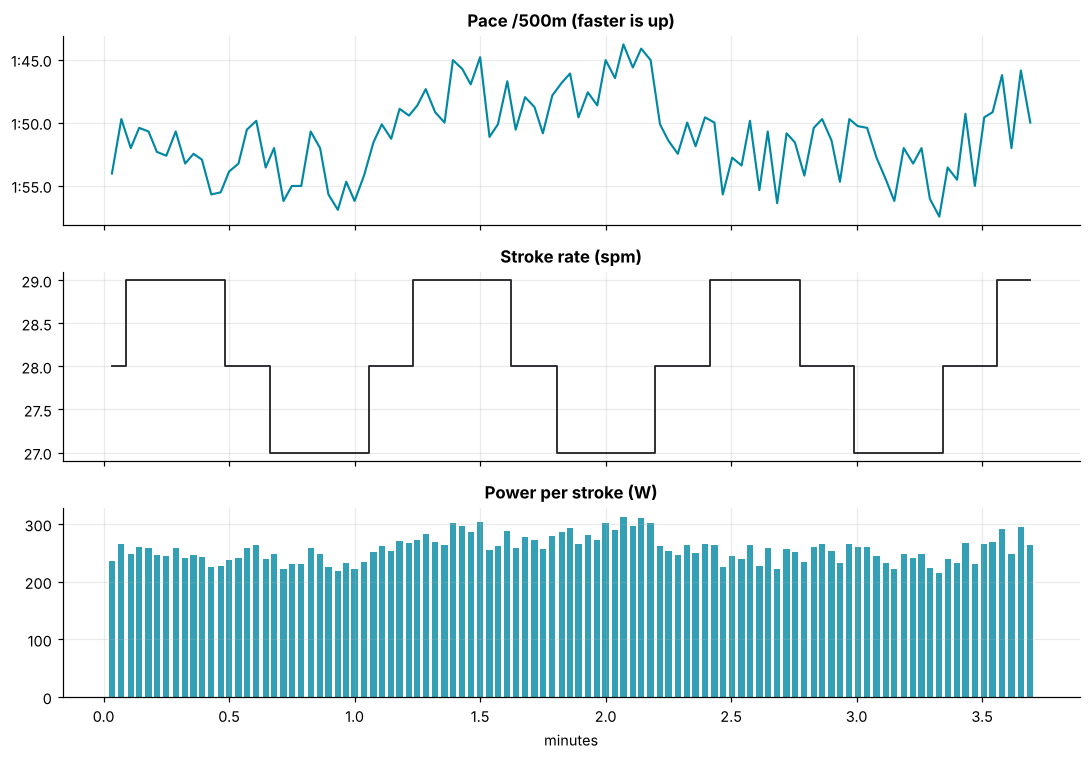

In [4]:
fw.plot_overview(s);

## First, middle and last third
The quickest way to see fade. Lower power or peak force in the last third, or a lower curve match, usually means fatigue.
`peak_at_%` is where in the drive the peak force arrives (0 = catch, 100 = finish); a later peak means a softer catch.

In [5]:
fw.thirds(s).style.format({'pace': fw.fmt_pace, 'watts': '{:.0f}', 'rate': '{:.1f}', 'm_per_stroke': '{:.2f}', 'peak_force': '{:.0f}',
    'drive_time': '{:.2f}', 'ratio': '1 : {:.1f}', 'peak_at_%': '{:.0f}', 'power_cv_%': '{:.1f}', 'curve_match_%': '{:.1f}'})

,pace,watts,rate,m_per_stroke,peak_force,drive_time,ratio,peak_at_%,power_cv_%,curve_match_%
part,,,,,,,,,,
first third,1:52.5,246,28.0,9.56,686,0.82,1 : 1.6,38,6.1,94.1
middle third,1:48.2,276,28.0,9.90,769,0.82,1 : 1.6,39,7.4,91.4
last third,1:52.0,249,28.1,9.61,698,0.82,1 : 1.6,38,7.6,94.5


## Force curve
Average handle force through the drive for each third (shaded: ±1σ of the first third). If the later curves sit below the
first, force fell; if their peak moves right, the peak came later in the drive.

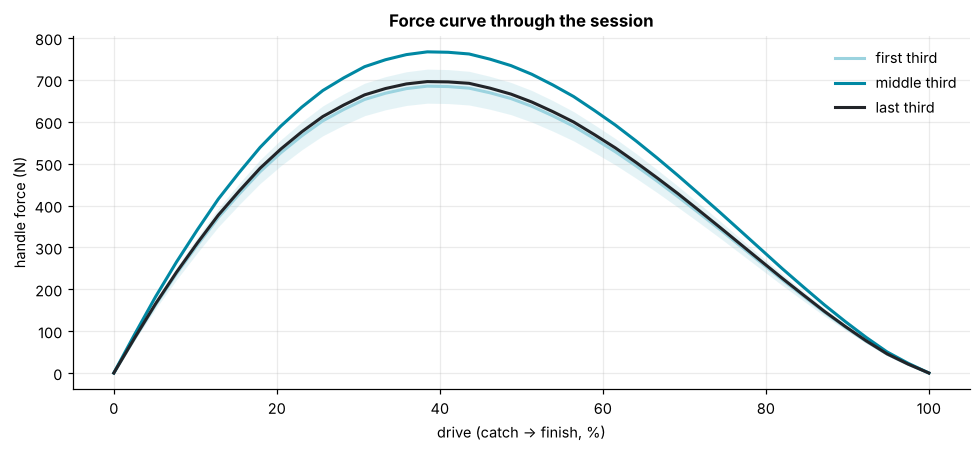

In [6]:
fw.plot_force(s);

## Consistency
Curve match compares each stroke's force curve with your session average (100 % = identical); power CV is the stroke-to-stroke
variation of power. Higher match and lower CV mean more repeatable strokes.

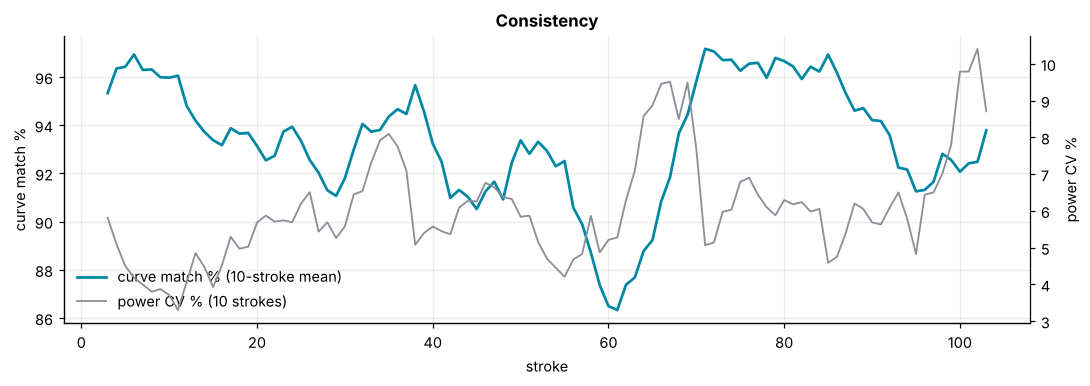

In [7]:
fw.plot_consistency(s);

## Effective work
Joules per stroke at each stroke rate. Higher means more work per stroke. If the median line falls as rate rises, extra rate
shortened the strokes rather than adding power; flat or rising means rate added power.

,strokes,J_per_stroke,m_per_stroke,watts
spm,,,,
27,32,534,9.80,249
28,35,555,10.10,259
29,36,552,9.90,258


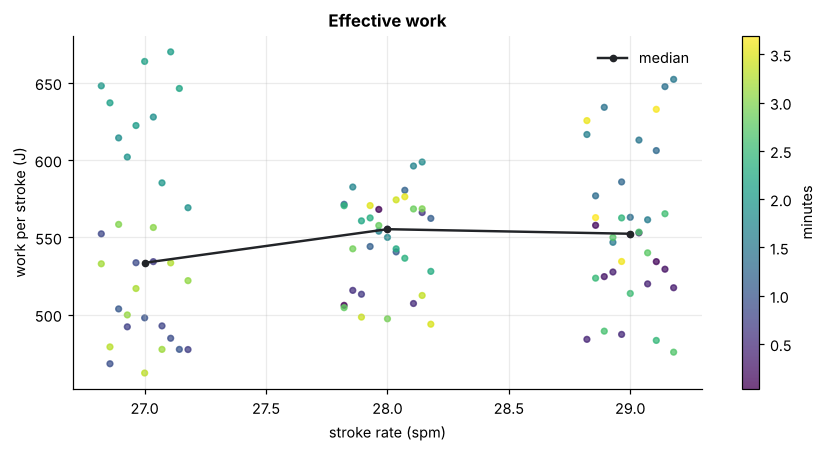

In [8]:
fw.plot_effective(s)
fw.effective_work(s).style.format({'J_per_stroke': '{:.0f}', 'm_per_stroke': '{:.2f}', 'watts': '{:.0f}'})

## Replay
Every stroke in order: its force curve against your average, and where it sits in the piece. Use the controls to play,
step or scrub. For long sessions set `every=2` (or more) to keep the animation light.

In [ ]:
HTML(fw.replay(s, every=1, fps=8).to_jshtml(default_mode='once'))

## Summary for Claude
`write_outputs` saves two files next to the export:

- **`<name>_summary.md`**: the numbers above as a short text summary (about 1–2 k tokens) plus a suggested prompt.
  Paste or attach it in a chat with Claude and ask for feedback.
- **`<name>_compact.json`**: the export without the per-stroke force curves (the bulk of the file), with one average curve per
  third. Attach it too if you want Claude to look at individual strokes.

The full export works as well; it is just several times larger.

In [10]:
md_path, json_path = fw.write_outputs(s)
print('wrote', md_path, 'and', json_path)
display(Markdown(md_path.read_text()))

wrote sample/flywheel-sample-1k_summary.md and sample/flywheel-sample-1k_compact.json


# Rowing session — summary for feedback

Recorded on a Concept2 rowing machine (PM5 monitor) with the Flywheel app. All values come from the monitor.
Units: pace = time per 500 m (min:s); power in watts; force in newtons; rate in strokes per minute (spm).

## Result
- **piece**: 1k
- **date**: 2026-11-05 21:05
- **time**: 3:42.2
- **distance m**: 1001
- **avg pace**: 1:51.0
- **avg watts**: 257
- **max watts**: 313
- **avg rate spm**: 28.0
- **strokes**: 103
- **m per stroke**: 9.72
- **work kJ**: 56.7
- **avg hr**: 169
- **drag factor**: 118
- **avg peak force N**: 717
- **avg drive length m**: 1.41
- **drive recovery ratio**: 1 : 1.6
- **power cv %**: 8.8
- **curve match %**: 93.3

## Splits (100 m)
| split | time | pace | watts | rate | strokes | m_per_stroke | peak_force |
|---|---|---|---|---|---|---|---|
| 100 m | 0:22.5 | 1:52.7 | 250 | 28.8 | 10 | 10.0 | 701 |
| 200 m | 0:22.4 | 1:51.8 | 241 | 28.1 | 10 | 10.0 | 672 |
| 300 m | 0:22.7 | 1:53.3 | 238 | 27.2 | 11 | 9.1 | 667 |
| 400 m | 0:21.6 | 1:48.2 | 276 | 28.7 | 10 | 10.0 | 770 |
| 500 m | 0:21.8 | 1:49.0 | 274 | 28.3 | 10 | 10.0 | 760 |
| 600 m | 0:21.4 | 1:46.9 | 293 | 27.0 | 10 | 10.0 | 815 |
| 700 m | 0:22.3 | 1:51.4 | 252 | 28.5 | 11 | 9.1 | 706 |
| 800 m | 0:22.4 | 1:52.1 | 246 | 28.5 | 10 | 10.0 | 693 |
| 900 m | 0:22.9 | 1:54.3 | 242 | 27.1 | 11 | 9.1 | 671 |
| 1,000 m | 0:22.1 | 1:50.7 | 260 | 28.4 | 10 | 10.0 | 730 |

## First / middle / last third of the strokes
| part | pace | watts | rate | m_per_stroke | peak_force | drive_time | ratio | peak_at_% | power_cv_% | curve_match_% |
|---|---|---|---|---|---|---|---|---|---|---|
| first third | 1:52.5 | 246 | 28.0 | 9.6 | 686 | 0.82 | 1 : 1.6 | 38.5 | 6.1 | 94.1 |
| middle third | 1:48.2 | 276 | 28.0 | 9.9 | 769 | 0.82 | 1 : 1.6 | 38.7 | 7.4 | 91.4 |
| last third | 1:52.0 | 249 | 28.1 | 9.6 | 698 | 0.82 | 1 : 1.6 | 38.5 | 7.6 | 94.5 |

## Force curve
- Peak force arrives on average at 39% of the drive (0% = catch, 100% = finish).
- Average curve (N, 10 points catch → finish): 0, 342, 578, 698, 707, 625, 479, 302, 127, 0
- Curve match % compares each stroke's force curve with the session average (100 = identical).

## Work per stroke by rate
| rate_spm | strokes | J_per_stroke | m_per_stroke | watts |
|---|---|---|---|---|
| 27 | 32 | 534 | 9.80 | 249 |
| 28 | 35 | 555 | 10.10 | 259 |
| 29 | 36 | 552 | 9.90 | 258 |

## How to read these numbers
- Even splits mean even pacing; a slower last third with a lower peak force or curve match usually means fatigue.
- Power CV % is the stroke-to-stroke variation of power: lower is more consistent.
- Metres per stroke at the same rate: higher means each stroke moved the boat further.
- A higher drag factor feels heavier per stroke; it is a machine setting, not effort.

---

## Suggested prompt

I'm attaching a summary of one rowing session on a Concept2 erg (and optionally the full export).
Please act as an experienced rowing coach. Based only on the data:
1. How was my pacing? Point to specific splits.
2. What does the force curve and its change over the session suggest about technique and fatigue?
3. How consistent were my strokes, and where did it break down?
4. Two or three concrete things to try in my next session of this piece.
Say which conclusions are uncertain because the data can't show them (e.g. posture or sequencing).
